In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

# Cargamos los archivos desde tu carpeta en Drive
df_clientes = pd.read_csv('/content/drive/MyDrive/Proyectos Data Science/olist_customers_dataset.csv')
df_pedidos = pd.read_csv('/content/drive/MyDrive/Proyectos Data Science/olist_orders_dataset.csv')

# Verificamos que carguen bien
print("--- CLIENTES ---")
print(df_clientes.head())

print("\n--- PEDIDOS ---")
print(df_pedidos.info())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- CLIENTES ---
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  

--- PE

In [4]:
# Cargamos también la tabla de pagos o items si la tenés, por ahora unimos clientes y pedidos
df_merged = pd.merge(df_pedidos, df_clientes, on='customer_id', how='inner')

# Vemos las primeras filas del dataframe unificado
print("Dimensiones del DataFrame unificado:", df_merged.shape)
print(df_merged.head(3))

# Verificamos si hay valores nulos (missing values) que debamos limpiar
print("\nValores nulos por columna:")
print(df_merged.isnull().sum())

Dimensiones del DataFrame unificado: (99441, 12)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15:27:45   
2          2018-08-08 13:50:00           2018-08-17 18:06:29   

  order_estimated_delivery_date                customer_unique_id  \
0           2017-10-18 00:00:00  7c396fd4830fd04220f754e42b4e5bff   
1     

In [5]:
# Cargamos la tabla de pagos para obtener el valor monetario de las compras
df_pagos = pd.read_csv('/content/drive/MyDrive/Proyectos Data Science/olist_order_payments_dataset.csv')

print("--- PAGOS ---")
print(df_pagos.head())
print("\nDimensiones de la tabla de pagos:", df_pagos.shape)

--- PAGOS ---
                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  

Dimensiones de la tabla de pagos: (103886, 5)


In [6]:
import datetime as dt

# 1. Agrupamos los pagos por order_id por si un pedido tiene cuotas o pagos múltiples
df_pagos_total = df_pagos.groupby('order_id')['payment_value'].sum().reset_index()

# 2. Unimos los pagos al dataframe principal (clientes + pedidos)
df_full = pd.merge(df_merged, df_pagos_total, on='order_id', how='inner')

# 3. Convertimos la fecha de compra a formato fecha (datetime)
df_full['order_purchase_timestamp'] = pd.to_datetime(df_full['order_purchase_timestamp'])

# Definimos una fecha de referencia (un día después de la última compra registrada en el dataset)
fecha_referencia = df_full['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# 4. Agrupamos por cliente único para calcular RFM
df_rfm = df_full.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (fecha_referencia - x.max()).days, # Recencia
    'order_id': 'count', # Frecuencia
    'payment_value': 'sum' # Monetario
}).reset_index()

# Renombramos las columnas para que queden claras
df_rfm.columns = ['customer_unique_id', 'Recencia', 'Frecuencia', 'Monetario']

print("--- VISTA PREVIA DE LA TABLA RFM ---")
print(df_rfm.head(10))
print("\nDimensiones de la tabla RFM (clientes únicos):", df_rfm.shape)

--- VISTA PREVIA DE LA TABLA RFM ---
                 customer_unique_id  Recencia  Frecuencia  Monetario
0  0000366f3b9a7992bf8c76cfdf3221e2       161           1     141.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f       164           1      27.19
2  0000f46a3911fa3c0805444483337064       586           1      86.22
3  0000f6ccb0745a6a4b88665a16c9f078       370           1      43.62
4  0004aac84e0df4da2b147fca70cf8255       337           1     196.89
5  0004bd2a26a76fe21f786e4fbd80607f       195           1     166.98
6  00050ab1314c0e55a6ca13cf7181fecf       181           1      35.38
7  00053a61a98854899e70ed204dd4bafe       232           1     419.18
8  0005e1862207bf6ccc02e4228effd9a0       592           1     150.12
9  0005ef4cd20d2893f0d9fbd94d3c0d97       220           1     129.76

Dimensiones de la tabla RFM (clientes únicos): (96095, 4)


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Aplicamos transformación logarítmica para manejar valores extremos (outliers)
df_rfm_log = np.log1p(df_rfm[['Recencia', 'Frecuencia', 'Monetario']])

# 2. Escalamos los datos (media 0 y desviación estándar 1)
scaler = StandardScaler()
df_rfm_scaled = scaler.fit_transform(df_rfm_log)

# 3. Aplicamos K-Means (definimos 4 grupos o clústeres de clientes)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_rfm['Cluster'] = kmeans.fit_predict(df_rfm_scaled)

# 4. Analizamos el comportamiento promedio de cada clúster
print("--- RESUMEN DE CLÚSTERES DE CLIENTES ---")
cluster_summary = df_rfm.groupby('Cluster').agg({
    'Recencia': 'mean',
    'Frecuencia': 'mean',
    'Monetario': ['mean', 'count']
}).round(2)

print(cluster_summary)

--- RESUMEN DE CLÚSTERES DE CLIENTES ---
        Recencia Frecuencia Monetario       
            mean       mean      mean  count
Cluster                                     
0         333.99       1.00    324.01  28512
1         368.65       1.00     70.14  39208
2         269.21       2.12    314.99   2997
3         116.71       1.00    121.23  25378


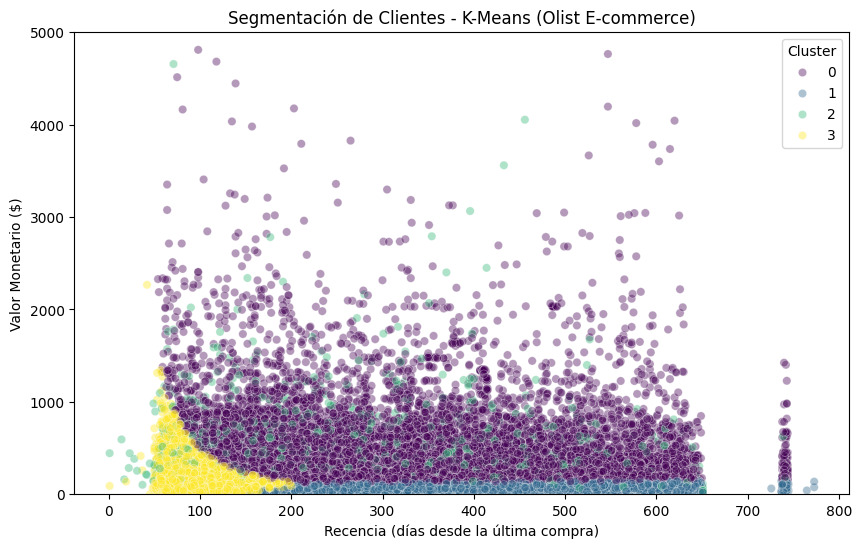

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico de dispersión entre Recencia y Monetario según el Clúster
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_rfm, x='Recencia', y='Monetario', hue='Cluster', palette='viridis', alpha=0.4)
plt.ylim(0, 5000)
plt.title('Segmentación de Clientes - K-Means (Olist E-commerce)')
plt.xlabel('Recencia (días desde la última compra)')
plt.ylabel('Valor Monetario ($)')
plt.show()

Mediante el uso de un modelo de K-Means Clustering sobre un dataset de más de 96.000 clientes de Olist, se identificaron 4 perfiles clave. Destaca el Clúster de clientes VIP/Fieles y los segmentos inactivos, permitiendo orientar futuras campañas de marketing y retención.